# Lab 1 – Introduction to Deep Learning (AI & Cybersecurity)
## Task 1 – Preprocessing

Goal: inspect the CICIDS2017 subset, decide how to clean it, how to split it into train/validation/test partitions, and which scaling strategy to apply, **justifying every choice with observed numbers**.

Notebook outline:
1. Setup and data loading
2. Inspection (samples, classes, data quality)
3. Cleaning (`NaN`/`inf`, impossible values, duplicates) with before/after counts
4. Train / validation / test split (stratified?)
5. Scaling (distributions, tails, choice)
6. Reusable `preprocess()` function (to be reused in Task 3 without `Destination Port`)
7. Answers to Task 1 questions

## 1. Setup

In [1]:
import os, warnings, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, RobustScaler

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)

DATA_PATH = "dataset_lab_1.csv"
assert os.path.exists(DATA_PATH), f"Dataset not found: {DATA_PATH}"
OUT_DIR = "task1_outputs"
os.makedirs(OUT_DIR, exist_ok=True)

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
print("Data:", DATA_PATH)

Data: dataset_lab_1.csv


## 2. Inspection

In [2]:
df = pd.read_csv(DATA_PATH)
LABEL = "Label"
FEATURES = [c for c in df.columns if c != LABEL]
print(f"Rows: {len(df):,}   Features: {len(FEATURES)}   Classes: {df[LABEL].nunique()}")
df.head()

Rows: 31,507   Features: 16   Classes: 4


,Flow Duration,Flow IAT Mean,Fwd PSH Flags,Bwd Packet Length Mean,Bwd Packet Length Max,Flow Bytes/s,Down/Up Ratio,SYN Flag Count,Fwd Packet Length Mean,Fwd IAT Std,Packet Length Mean,Fwd Packet Length Max,Subflow Fwd Packets,Flow Packets/s,Total Fwd Packets,Destination Port,Label
0,303376,30337.600000,0,749.4,1448,12743.263,0,0,19.833334,98776.15,322.16666,119,6,36.258636,6,443,Benign
1,117,117.000000,0,0.0,0,0.000,1,0,0.000000,0.00,0.00000,0,1,17094.018000,1,52631,Benign
2,142,142.000000,0,0.0,0,84507.040,0,0,6.000000,0.00,6.00000,6,2,14084.507000,2,80,Benign
3,191,63.666668,0,52.0,52,921465.940,1,0,36.000000,0.00,42.40000,36,2,20942.408000,2,53,Benign
4,4,4.000000,0,0.0,0,3000000.000,0,0,6.000000,0.00,6.00000,6,2,500000.000000,2,49467,Benign


,n,%
Label,,
Benign,20000,63.48
DoS Hulk,5000,15.87
PortScan,5000,15.87
Brute Force,1507,4.78


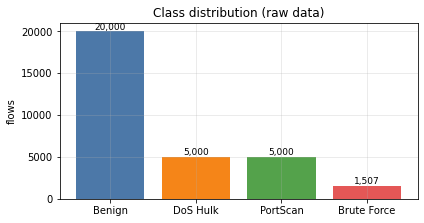

In [3]:
counts = df[LABEL].value_counts()
summary = pd.DataFrame({"n": counts, "%": (counts / len(df) * 100).round(2)})
display(summary)

fig, ax = plt.subplots(figsize=(6, 3.2))
bars = ax.bar(summary.index, summary["n"], color=["#4c78a8", "#f58518", "#54a24b", "#e45756"])
for b, n in zip(bars, summary["n"]):
    ax.text(b.get_x() + b.get_width() / 2, n, f"{n:,}", ha="center", va="bottom", fontsize=9)
ax.set_title("Class distribution (raw data)")
ax.set_ylabel("flows")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/fig_class_balance_raw.png")
plt.show()

### 2.1 Data quality checks

In [4]:
n_nan_rows = df.isna().any(axis=1).sum()
inf_mask = np.isinf(df[FEATURES]).any(axis=1)
nan_inf_mask = df[FEATURES].replace([np.inf, -np.inf], np.nan).isna().any(axis=1)
neg_mask = (df[FEATURES] < 0).any(axis=1)
dup_mask = df.duplicated()

print("NaN per column                  :", df.isna().sum()[df.isna().sum() > 0].to_dict())
print("Rows with NaN                   :", n_nan_rows)
print("Rows with +/-inf                :", inf_mask.sum(), "  (per column:", np.isinf(df[FEATURES]).sum()[np.isinf(df[FEATURES]).sum() > 0].to_dict(), ")")
print("Rows with NaN or inf (union)    :", nan_inf_mask.sum(), "  (all have Flow Duration == 0:", bool((df.loc[nan_inf_mask, "Flow Duration"] == 0).all()), ")")
print("Rows with negative values       :", neg_mask.sum(), "  (columns:", (df[FEATURES] < 0).sum()[(df[FEATURES] < 0).sum() > 0].to_dict(), ")")
print("Exact duplicate rows (extra)    :", dup_mask.sum())

# Feature-identical rows with conflicting labels (after removing NaN/inf, negative rows, and exact full-row duplicates)
df_valid_dedup = df[~nan_inf_mask & ~neg_mask].drop_duplicates()
feat_label_nunique = df_valid_dedup.groupby(FEATURES)[LABEL].nunique()
conflict_groups = feat_label_nunique[feat_label_nunique > 1]
conflict_rows = df_valid_dedup[df_valid_dedup.duplicated(subset=FEATURES, keep=False)]
print(
    f"Conflicting-label feature pairs : {len(conflict_groups)} ({len(conflict_rows)} rows, "
    f"labels={conflict_rows[LABEL].value_counts().to_dict()}, "
    f"ports={conflict_rows['Destination Port'].unique().tolist()})"
)

port0_mask = df["Destination Port"] == 0
print("Rows with Destination Port == 0 :", int(port0_mask.sum()), "  (by class:", df.loc[port0_mask, LABEL].value_counts().to_dict(), ")")
print("Constant columns                :", [c for c in FEATURES if df[c].nunique() <= 1])

print("\nIdentical column pairs:")
for i, a in enumerate(FEATURES):
    for b in FEATURES[i + 1:]:
        if (df[a] == df[b]).all():
            print(f"  {a}  ==  {b}")

q = pd.DataFrame({
    "NaN/inf": df[nan_inf_mask][LABEL].value_counts(),
    "negative": df[neg_mask][LABEL].value_counts(),
    "duplicates (extra)": df[dup_mask][LABEL].value_counts(),
}).fillna(0).astype(int)
q["class_n"] = counts
q["% dup within class"] = (q["duplicates (extra)"] / q["class_n"] * 100).round(1)
print("\nIssues per class:")
display(q)

NaN per column                  : {'Flow Bytes/s': 20}
Rows with NaN                   : 20
Rows with +/-inf                : 27   (per column: {'Flow Bytes/s': 7, 'Flow Packets/s': 27} )
Rows with NaN or inf (union)    : 27   (all have Flow Duration == 0: True )


Rows with negative values       : 2   (columns: {'Flow Duration': 2, 'Flow IAT Mean': 2, 'Flow Bytes/s': 2, 'Flow Packets/s': 2} )
Exact duplicate rows (extra)    : 2111
Conflicting-label feature pairs : 7 (14 rows, labels={'Benign': 7, 'DoS Hulk': 7}, ports=[80])
Rows with Destination Port == 0 : 10   (by class: {'Benign': 10} )
Constant columns                : []

Identical column pairs:
  Fwd PSH Flags  ==  SYN Flag Count
  Subflow Fwd Packets  ==  Total Fwd Packets

Issues per class:


,NaN/inf,negative,duplicates (extra),class_n,% dup within class
Label,,,,,
Benign,8,2,750,20000,3.8
Brute Force,0,0,80,1507,5.3
DoS Hulk,18,0,1131,5000,22.6
PortScan,1,0,150,5000,3.0


**Interpretation of findings.**
- `inf` values are not detected by `isna()`, so they must be converted to `NaN` first. The 20 rows with `NaN` in `Flow Bytes/s` are a subset of the 27 non-finite rows, and all 27 have `Flow Duration == 0`, making flow rates (`Flow Bytes/s`, `Flow Packets/s`) undefined due to division by zero.
- `NaN/inf` rows are concentrated in **DoS Hulk** (18 of 27); the 2 negative rows (`Flow Duration = -1`, both `Benign`) are physically impossible measurement artifacts.
- Duplicate rates vary substantially across classes: **DoS Hulk** has the largest share both in absolute count (1,131) and percentage (22.6%).
- Two pairs of columns are identical (`Fwd PSH Flags == SYN Flag Count`, `Subflow Fwd Packets == Total Fwd Packets`): redundant features, harmless for an FFNN, but important to document.
- **Conflicting labels:** after removing non-finite/negative rows and exact full-row duplicates, 7 feature-identical pairs (14 rows, ~0.05% of the cleaned data) carry identical 16-feature vectors with opposing labels (`Benign` vs `DoS Hulk`, all on port 80).
- **Zero destination port:** 10 `Benign` flows have `Destination Port == 0` (non-TCP/UDP protocols or flow-exporter artifacts; retained as valid benign traffic).

### 2.2 `Destination Port` by class (observation for Task 3)

In [5]:
port_info = df.groupby(LABEL)["Destination Port"].agg(
    n_distinct_ports="nunique",
    top_port=lambda s: s.value_counts().index[0],
    top_port_share=lambda s: round(s.value_counts().iloc[0] / len(s), 3),
)
display(port_info)

,n_distinct_ports,top_port,top_port_share
Label,,,
Benign,3603,53,0.426
Brute Force,1,80,1.000
DoS Hulk,1,80,1.000
PortScan,995,5631,0.003


## 3. Cleaning

**Decisions**
1. **Convert `+/-inf` to `NaN`, then drop rows with `NaN`.** This removes 27 rows (0.09%), all with `Flow Duration == 0` where flow rates are undefined by division by zero: there is no "true" rate to reconstruct, and imputing (mean/median) would fabricate plausible rates for degenerate zero-duration flows. Given the negligible loss, dropping them is the cleanest and most honest choice.
2. **Drop rows with negative values** (2 `Benign` rows): negative duration, IAT, and rates are physically impossible measurement artifacts.
3. **Drop exact full-row duplicates *before* splitting.** Identical rows appearing in both train and validation/test would let the model memorize them and artificially inflate evaluation metrics (data leakage). The 7 feature-identical pairs with conflicting labels (`Benign` vs `DoS Hulk`, 14 rows = 0.05%) are retained rather than arbitrarily relabelled or dropped: without packet payloads or timestamps we cannot determine the ground-truth label, their impact is negligible, and keeping standard full-row `drop_duplicates()` ensures consistent behavior when re-running the pipeline without `Destination Port` in Task 3 (where we will revisit deduplication given its dramatic effect on class balance).
4. **Redundant identical columns:** retained to preserve feature comparability across baseline experiments, and explicitly documented.

In [6]:
def clean(df_in, verbose=True):
    log = {}
    d = df_in.copy()
    feats = [c for c in d.columns if c != LABEL]
    log["0_raw"] = d[LABEL].value_counts()

    d[feats] = d[feats].replace([np.inf, -np.inf], np.nan)
    d = d.dropna()
    log["1_after_NaN_inf"] = d[LABEL].value_counts()

    d = d[~(d[feats] < 0).any(axis=1)]
    log["2_after_negative"] = d[LABEL].value_counts()

    d = d.drop_duplicates()
    log["3_after_dedup"] = d[LABEL].value_counts()

    table = pd.DataFrame(log).fillna(0).astype(int)
    table.loc["TOTAL"] = table.sum()
    if verbose:
        display(table)
    return d.reset_index(drop=True), table

df_clean, clean_table = clean(df)
n0, n1 = clean_table.loc["TOTAL", "0_raw"], clean_table.loc["TOTAL", "3_after_dedup"]
print(f"Samples BEFORE cleaning: {n0:,}   AFTER: {n1:,}   (removed {n0 - n1:,} = {100 * (n0 - n1) / n0:.1f}%)")

,0_raw,1_after_NaN_inf,2_after_negative,3_after_dedup
Label,,,,
Benign,20000,19992,19990,19240
Brute Force,1507,1507,1507,1427
DoS Hulk,5000,4982,4982,3868
PortScan,5000,4999,4999,4849
TOTAL,31507,31480,31478,29384


Samples BEFORE cleaning: 31,507   AFTER: 29,384   (removed 2,123 = 6.7%)


In [7]:
rows = []
for cls in clean_table.index[:-1]:
    a, b = clean_table.loc[cls, "0_raw"], clean_table.loc[cls, "3_after_dedup"]
    rows.append({"class": cls, "before": a, "after": b, "removed %": round(100 * (a - b) / a, 1)})
display(pd.DataFrame(rows).set_index("class"))

,before,after,removed %
class,,,
Benign,20000,19240,3.8
Brute Force,1507,1427,5.3
DoS Hulk,5000,3868,22.6
PortScan,5000,4849,3.0


## 4. Train / validation / test split

**Choice:** 70% train / 15% validation / 15% test, **stratified** on `Label`, with a fixed random seed (`SEED = 42`).

**Why stratify?** `Brute Force` is the minority class (~4.9% after cleaning). Without stratification, its count in validation/test fluctuates by chance across random seeds—making evaluation metrics noisy on the very class that is hardest to detect. The simulation below quantifies this variance.

In [8]:
y_all = df_clean[LABEL]
idx = np.arange(len(df_clean))

# Experiment: how much does the Brute Force count in validation fluctuate without stratification?
bf_counts = []
for s in range(200):
    tr, tmp = train_test_split(idx, test_size=0.30, random_state=s)
    va, te = train_test_split(tmp, test_size=0.50, random_state=s)
    bf_counts.append((y_all.iloc[va] == "Brute Force").sum())
bf_counts = np.array(bf_counts)

tr, tmp = train_test_split(idx, test_size=0.30, random_state=SEED, stratify=y_all)
va, te = train_test_split(tmp, test_size=0.50, random_state=SEED, stratify=y_all.iloc[tmp])
print(f"Brute Force in validation WITHOUT stratification (200 seeds): min={bf_counts.min()}, max={bf_counts.max()}, mean={bf_counts.mean():.1f}")
print(f"Brute Force in validation WITH stratification               : {(y_all.iloc[va] == 'Brute Force').sum()}")

split_tbl = pd.DataFrame({
    "train": y_all.iloc[tr].value_counts(),
    "val": y_all.iloc[va].value_counts(),
    "test": y_all.iloc[te].value_counts(),
})
split_pct = (split_tbl / split_tbl.sum() * 100).round(2)
split_tbl.loc["TOTAL"] = split_tbl.sum()
print("\nCounts per partition:")
display(split_tbl)
print("Class percentages within each partition:")
display(split_pct)

Brute Force in validation WITHOUT stratification (200 seeds): min=178, max=252, mean=216.1
Brute Force in validation WITH stratification               : 214

Counts per partition:


,train,val,test
Label,,,
Benign,13467,2886,2887
PortScan,3394,728,727
DoS Hulk,2708,580,580
Brute Force,999,214,214
TOTAL,20568,4408,4408


Class percentages within each partition:


,train,val,test
Label,,,
Benign,65.48,65.47,65.49
PortScan,16.50,16.52,16.49
DoS Hulk,13.17,13.16,13.16
Brute Force,4.86,4.85,4.85


## 5. Scaling

Before choosing a scaling strategy, I inspect feature ranges, percentiles, and tails **on the training set only** (any statistic used to choose or fit a transformation must come exclusively from the training partition).

In [9]:
Xtr_raw = df_clean.loc[tr, FEATURES]

desc = Xtr_raw.describe(percentiles=[.5, .99]).T[["min", "50%", "99%", "max"]]
desc["max/median"] = (desc["max"] / desc["50%"].replace(0, np.nan)).round(1)
desc["skew"] = Xtr_raw.skew().round(1)
desc["n_unique"] = Xtr_raw.nunique()
display(desc.sort_values("skew", ascending=False))

,min,50%,99%,max,max/median,skew,n_unique
Subflow Fwd Packets,1.000000,2.000000,5.000000e+01,3.141000e+03,1570.5,64.4,139
Total Fwd Packets,1.000000,2.000000,5.000000e+01,3.141000e+03,1570.5,64.4,139
Flow Bytes/s,0.000000,5250.039350,1.233333e+07,2.070000e+09,394282.8,44.3,13426
Fwd Packet Length Mean,0.000000,34.000000,3.731191e+02,2.361160e+03,69.4,10.7,2960
Fwd Packet Length Max,0.000000,37.000000,2.012990e+03,1.163200e+04,314.4,8.5,1086
Flow IAT Mean,0.500000,10856.166500,1.871918e+07,1.140000e+08,10500.9,7.4,12663
Flow Packets/s,0.017486,118.779997,7.500000e+05,3.000000e+06,25256.8,7.3,12755
SYN Flag Count,0.000000,0.000000,1.000000e+00,1.000000e+00,NaN,4.7,2
Fwd PSH Flags,0.000000,0.000000,1.000000e+00,1.000000e+00,NaN,4.7,2
Fwd IAT Std,0.000000,0.000000,4.910000e+07,8.280000e+07,NaN,2.5,5916


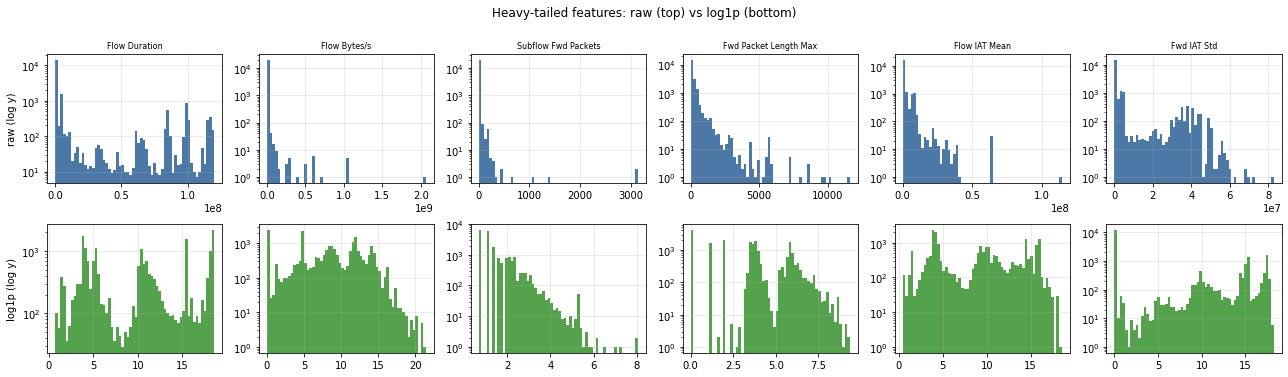

In [10]:
BINARY_OR_SMALL = ["Fwd PSH Flags", "SYN Flag Count", "Down/Up Ratio"]
CATEGORICAL_LIKE = ["Destination Port"]
LOG_FEATURES = [c for c in FEATURES if c not in BINARY_OR_SMALL + CATEGORICAL_LIKE]

heavy = ["Flow Duration", "Flow Bytes/s", "Subflow Fwd Packets", "Fwd Packet Length Max", "Flow IAT Mean", "Fwd IAT Std"]
fig, axes = plt.subplots(2, len(heavy), figsize=(3.0 * len(heavy), 5.2))
for j, c in enumerate(heavy):
    axes[0, j].hist(Xtr_raw[c], bins=60, color="#4c78a8")
    axes[0, j].set_yscale("log")
    axes[0, j].set_title(c, fontsize=8)
    axes[1, j].hist(np.log1p(Xtr_raw[c]), bins=60, color="#54a24b")
    axes[1, j].set_yscale("log")
axes[0, 0].set_ylabel("raw (log y)")
axes[1, 0].set_ylabel("log1p (log y)")
plt.suptitle("Heavy-tailed features: raw (top) vs log1p (bottom)", y=1.0)
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/fig_distributions_raw_vs_log.png")
plt.show()

**Quantitative comparison of three scaling strategies.** For each strategy (fitted on the training set), I measure what fraction of training values fall beyond ±5 standard deviations (or ±5 IQR for `RobustScaler`) and the maximum absolute scaled value: larger values indicate a scale distorted by outliers.

In [11]:
def frac_extreme(Z, thr=5.0):
    return float((np.abs(Z) > thr).mean())

def make_log(df_x):
    d = df_x.copy()
    d[LOG_FEATURES] = np.log1p(d[LOG_FEATURES])
    return d

Z_std = StandardScaler().fit(Xtr_raw).transform(Xtr_raw)
Z_rob = RobustScaler().fit(Xtr_raw).transform(Xtr_raw)
Xtr_log = make_log(Xtr_raw)
Z_logstd = StandardScaler().fit(Xtr_log).transform(Xtr_log)

cmp_tbl = pd.DataFrame({
    "Standard": [frac_extreme(Z_std), np.abs(Z_std).max()],
    "Robust": [frac_extreme(Z_rob), np.abs(Z_rob).max()],
    "log1p + Standard": [frac_extreme(Z_logstd), np.abs(Z_logstd).max()],
}, index=["% values with |z|>5", "max |z|"]).T
cmp_tbl["% values with |z|>5"] = (cmp_tbl["% values with |z|>5"] * 100).round(2)
cmp_tbl["max |z|"] = cmp_tbl["max |z|"].round(1)
display(cmp_tbl)

skew_cmp = pd.DataFrame({
    "raw skew": Xtr_raw[LOG_FEATURES].skew(),
    "skew after log1p": Xtr_log[LOG_FEATURES].skew(),
}).round(1)
display(skew_cmp)

,% values with |z|>5,max |z|
Standard,0.23,85.2
Robust,8.19,13956.6
log1p + Standard,0.05,10.2


,raw skew,skew after log1p
Flow Duration,1.8,0.2
Flow IAT Mean,7.4,0.1
Bwd Packet Length Mean,2.1,-0.0
Bwd Packet Length Max,2.5,0.2
Flow Bytes/s,44.3,-0.3
Fwd Packet Length Mean,10.7,-0.4
Fwd IAT Std,2.5,0.7
Packet Length Mean,2.0,-0.1
Fwd Packet Length Max,8.5,-0.0
Subflow Fwd Packets,64.4,1.7


**Choice: `log1p` on non-negative continuous features + `StandardScaler`** (fitted on the training set only).

- Size, timing, and rate features span several orders of magnitude with extreme right tails on the training set (e.g., `Flow Duration`: median ~3.1×10⁴, max ~1.2×10⁸; `Flow Bytes/s`: skew 44.3, max ~2.1×10⁹; `Subflow Fwd Packets`: skew 64.4, max 3,141). Under pure `StandardScaler`, outliers dominate the mean and standard deviation: extreme flows stay at `max |z| = 85.2` (0.23% of values beyond |z| = 5) while compressing typical flows into a narrow band near zero.
- `RobustScaler` (median/IQR) performs worse on extreme values: **8.19% of training entries exceed |z| = 5 and `max |z|` reaches ~13,957**, because dividing by a very small or near-zero IQR (many features are zero-heavy) blows up the tails.
- `log1p` monotonically compresses heavy right tails while cleanly handling zeros (unlike `log`). After `log1p`, skewness drops sharply across all continuous features (the highest remaining is `Subflow Fwd Packets`/`Total Fwd Packets`, down from 64.4 to 1.7), reducing values beyond |z| = 5 to **0.05%** and `max |z|` to **10.2**. This transform is safe because cleaning already removed all negative values.
- **Excluded from `log1p`:** `Fwd PSH Flags` and `SYN Flag Count` (binary 0/1), `Down/Up Ratio` (small integer 0–6 on train), and `Destination Port` (port identifier rather than a physical quantity, so a log transform has no meaning). These receive only `StandardScaler`.

### 5.1 Why the scaler must be fitted only on the training set

If mean and standard deviation are computed across **all** data, validation and test statistics leak into the feature scaling: the model indirectly accesses information that is unavailable at deployment time. Below is the numerical difference on the estimated parameters. Here the shift is small (under 0.01 standard deviations on the mean) because the dataset is large and stratified, yet the methodological rule is strict: evaluation partitions must remain completely independent of preprocessing fit parameters, and on datasets with rare extreme outliers in validation/test, fitting on all data can visibly distort the scale.

In [12]:
Xall_log = make_log(df_clean[FEATURES])
sc_train = StandardScaler().fit(Xtr_log)
sc_all = StandardScaler().fit(Xall_log)

leak = pd.DataFrame({
    "mean (train)": sc_train.mean_, "mean (all)": sc_all.mean_,
    "std (train)": sc_train.scale_, "std (all)": sc_all.scale_,
}, index=FEATURES)
leak["Δ mean / std"] = ((leak["mean (all)"] - leak["mean (train)"]) / leak["std (train)"]).round(4)
display(leak.round(4).sort_values("Δ mean / std", key=np.abs, ascending=False).head(8))

,mean (train),mean (all),std (train),std (all),Δ mean / std
Flow Bytes/s,8.1443,8.1102,4.6477,4.6564,-0.0073
Fwd Packet Length Mean,2.7213,2.7087,1.7513,1.7557,-0.0072
SYN Flag Count,0.0405,0.0394,0.1972,0.1945,-0.0059
Fwd PSH Flags,0.0405,0.0394,0.1972,0.1945,-0.0059
Fwd Packet Length Max,3.2467,3.2332,2.2856,2.2893,-0.0059
Packet Length Mean,3.4332,3.4221,2.1698,2.1796,-0.0051
Bwd Packet Length Max,3.9286,3.9187,2.9183,2.9232,-0.0034
Bwd Packet Length Mean,3.5902,3.5834,2.5237,2.5307,-0.0027


## 6. Reusable `preprocess()` function

Encapsulates the entire pipeline (`clean -> stratified split -> log1p -> StandardScaler` fitted on train only) with no reliance on global feature lists. In Task 2B we can use the exported `X_*_raw` arrays for the unscaled baseline variant (S1), and in Task 3 we can call `preprocess(df, drop_port=True)` directly and use the saved scaler parameters for the port counterfactual.

In [13]:
def preprocess(df_in, drop_port=False, seed=SEED, dedup=True, test_size=0.15, val_size=0.15, verbose=True):
    d = df_in.copy()
    if drop_port:
        d = d.drop(columns="Destination Port")
    feats = [c for c in d.columns if c != LABEL]

    # Cleaning
    d[feats] = d[feats].replace([np.inf, -np.inf], np.nan)
    d = d.dropna()
    d = d[~(d[feats] < 0).any(axis=1)]
    if dedup:
        d = d.drop_duplicates()
    d = d.reset_index(drop=True)

    # Stratified split
    classes = sorted(d[LABEL].unique())
    cls2id = {c: i for i, c in enumerate(classes)}
    y = d[LABEL].map(cls2id).values
    i_tr, i_tmp = train_test_split(np.arange(len(d)), test_size=val_size + test_size, random_state=seed, stratify=y)
    i_va, i_te = train_test_split(i_tmp, test_size=test_size / (val_size + test_size), random_state=seed, stratify=y[i_tmp])

    # log1p + StandardScaler (fitted on train ONLY)
    binary_or_small = {"Fwd PSH Flags", "SYN Flag Count", "Down/Up Ratio"}
    categorical_like = {"Destination Port"}
    log_feats = [c for c in feats if c not in (binary_or_small | categorical_like)]

    def make_raw(ix):
        return d.loc[ix, feats].to_numpy(dtype="float32")

    def tf(ix):
        x = d.loc[ix, feats].copy()
        x[log_feats] = np.log1p(x[log_feats])
        return x

    X_tr, X_va, X_te = tf(i_tr), tf(i_va), tf(i_te)
    scaler = StandardScaler().fit(X_tr)
    out = {
        "X_train": scaler.transform(X_tr).astype("float32"), "y_train": y[i_tr],
        "X_val": scaler.transform(X_va).astype("float32"), "y_val": y[i_va],
        "X_test": scaler.transform(X_te).astype("float32"), "y_test": y[i_te],
        "X_train_raw": make_raw(i_tr),
        "X_val_raw": make_raw(i_va),
        "X_test_raw": make_raw(i_te),
        "features": feats, "classes": classes, "scaler": scaler, "log_features": log_feats,
        "class_counts_clean": d[LABEL].value_counts().to_dict(),
        "df_clean": d, "indices": {"train": i_tr, "val": i_va, "test": i_te},
    }
    if verbose:
        print(f"drop_port={drop_port} dedup={dedup}  |  clean samples: {len(d):,}  train/val/test: {len(i_tr):,}/{len(i_va):,}/{len(i_te):,}")
        print("classes:", cls2id)
        print("counts after cleaning:", out["class_counts_clean"])
    return out

data = preprocess(df, drop_port=False)
for k in ["X_train", "X_val", "X_test"]:
    print(f"{k:7s} {str(data[k].shape):12s}  mean={data[k].mean():+.4f}  std={data[k].std():.4f}")

drop_port=False dedup=True  |  clean samples: 29,384  train/val/test: 20,568/4,408/4,408
classes: {'Benign': 0, 'Brute Force': 1, 'DoS Hulk': 2, 'PortScan': 3}
counts after cleaning: {'Benign': 19240, 'PortScan': 4849, 'DoS Hulk': 3868, 'Brute Force': 1427}
X_train (20568, 16)   mean=+0.0000  std=1.0000
X_val   (4408, 16)    mean=-0.0034  std=1.0038
X_test  (4408, 16)    mean=-0.0149  std=0.9939


In [14]:
# Sanity checks: cross-split overlaps, NaN/inf verification, and artifact export
d_clean = data["df_clean"]
feats = data["features"]
i_tr, i_va, i_te = data["indices"]["train"], data["indices"]["val"], data["indices"]["test"]

def tuple_set(df_sub, cols):
    return set(df_sub[cols].itertuples(index=False, name=None))

def rows_hash(X):
    return {hashlib.md5(r.tobytes()).hexdigest() for r in X}

all_cols = feats + [LABEL]
fl_tr, fl_va, fl_te = tuple_set(d_clean.iloc[i_tr], all_cols), tuple_set(d_clean.iloc[i_va], all_cols), tuple_set(d_clean.iloc[i_te], all_cols)
print("1) Exact (features+label) overlap  | train∩val:", len(fl_tr & fl_va), "  train∩test:", len(fl_tr & fl_te), "  val∩test:", len(fl_va & fl_te))

f_tr, f_va, f_te = tuple_set(d_clean.iloc[i_tr], feats), tuple_set(d_clean.iloc[i_va], feats), tuple_set(d_clean.iloc[i_te], feats)
print("2) Exact features-only overlap     | train∩val:", len(f_tr & f_va), "  train∩test:", len(f_tr & f_te), "  val∩test:", len(f_va & f_te))

h_tr, h_va, h_te = rows_hash(data["X_train"]), rows_hash(data["X_val"]), rows_hash(data["X_test"])
print("3) Scaled float32 feature overlap  | train∩val:", len(h_tr & h_va), "  train∩test:", len(h_tr & h_te), "  val∩test:", len(h_va & h_te))
print("Note: exact deduplication removes all (features+label) overlaps (0/0/0). Two of the scaled float32 overlaps (1 in train∩test, 1 in val∩test) are the conflicting-label pairs (Benign vs DoS Hulk) identified in Section 2.1, while the remaining 2 in train∩test are distinct near-duplicate flows that collapse at float32 precision (negligible impact across 8,816 val+test rows).")

all_arrays = ["X_train", "X_val", "X_test", "X_train_raw", "X_val_raw", "X_test_raw"]
print("Any NaN/inf in scaled or raw splits:", any(not np.isfinite(data[k]).all() for k in all_arrays))

np.savez_compressed(
    f"{OUT_DIR}/task1_preprocessed_with_port.npz",
    X_train=data["X_train"], y_train=data["y_train"],
    X_val=data["X_val"], y_val=data["y_val"],
    X_test=data["X_test"], y_test=data["y_test"],
    X_train_raw=data["X_train_raw"],
    X_val_raw=data["X_val_raw"],
    X_test_raw=data["X_test_raw"],
    scaler_mean=data["scaler"].mean_,
    scaler_scale=data["scaler"].scale_,
    features=np.array(data["features"]),
    log_features=np.array(data["log_features"]),
    classes=np.array(data["classes"]),
)
clean_table.to_csv(f"{OUT_DIR}/cleaning_counts_by_class.csv")
print("Saved artifacts to", OUT_DIR)

1) Exact (features+label) overlap  | train∩val: 0   train∩test: 0   val∩test: 0
2) Exact features-only overlap     | train∩val: 0   train∩test: 1   val∩test: 1
3) Scaled float32 feature overlap  | train∩val: 0   train∩test: 3   val∩test: 1
Note: exact deduplication removes all (features+label) overlaps (0/0/0). Two of the scaled float32 overlaps (1 in train∩test, 1 in val∩test) are the conflicting-label pairs (Benign vs DoS Hulk) identified in Section 2.1, while the remaining 2 in train∩test are distinct near-duplicate flows that collapse at float32 precision (negligible impact across 8,816 val+test rows).
Any NaN/inf in scaled or raw splits: False


Saved artifacts to task1_outputs


## 7. Answers to Task 1 questions

**Inspect.** The dataset contains 31,507 flows, 16 numeric features, and 4 classes: `Benign` 20,000 (63.48%), `DoS Hulk` 5,000 (15.87%), `PortScan` 5,000 (15.87%), and `Brute Force` 1,507 (4.78%). Quality issues observed: 20 `NaN` entries in `Flow Bytes/s` and 27 rows with `+inf` (union = 27 rows, all with `Flow Duration == 0`, mostly `DoS Hulk`), 2 `Benign` rows with negative values (`Flow Duration = -1`), 2,111 exact duplicate rows (22.6% within `DoS Hulk`), 7 feature-identical pairs with conflicting labels (`Benign` vs `DoS Hulk` on port 80), 10 `Benign` rows with `Destination Port == 0`, and 2 pairs of identical columns (`Fwd PSH Flags == SYN Flag Count` and `Subflow Fwd Packets == Total Fwd Packets`). No constant columns exist.

**Q: How many samples do you have before and after your cleaning?** 31,507 (raw) → 31,480 (after `NaN`/`inf`, −27) → 31,478 (after negative values, −2) → **29,384** after exact deduplication (−2,123 total, or 6.7%). Per-class counts after cleaning: `Benign` 19,240, `PortScan` 4,849, `DoS Hulk` 3,868, `Brute Force` 1,427.

**Missing values & duplicates decisions.** `NaN`/`inf` rows: dropped (0.09% loss; zero-duration flows have undefined rates, so imputation would invent artificial values). Negative rows: dropped (physically impossible). Exact full-row duplicates: dropped before splitting to prevent train/validation/test leakage (this decision will be revisited in Task 3 once `Destination Port` is removed). The 7 feature-identical pairs with conflicting labels (0.05%) are retained since ground truth cannot be determined without payloads/timestamps and full-row deduplication keeps the Task 3 comparison consistent.

**Q: Should the split be stratified? Why?** Yes. `Brute Force` represents only ~4.9% of the cleaned data; without stratification, its validation count fluctuates between 178 and 252 across 200 seeds, destabilizing evaluation metrics on the rarest class. With a stratified 70/15/15 split (`SEED = 42`), every partition preserves the class proportions (`20,568 / 4,408 / 4,408` total; `999 / 214 / 214` for `Brute Force`).

**Q: Where did you fit the scaler, and what goes wrong if you fit it on all the data?** On the training set only; validation and test sets are transformed using the training parameters. Fitting on all data introduces data leakage from validation/test into preprocessing, producing overly optimistic generalization estimates that no longer reflect real deployment where unseen flows are not available during training. Even though the parameter shift here is small (`|Δ mean / std| < 0.008`), keeping preprocessing strictly fitted on train is essential methodologically.

**Q: Which scaling did you pick and why? How did the outliers inform the choice?** `log1p` on non-negative continuous features (all except the binary flags, `Down/Up Ratio`, and `Destination Port`) followed by `StandardScaler` fitted on train. Training features exhibit heavy right tails spanning several orders of magnitude (skew up to 64.4, max/median ratios up to ~3.9×10⁵): pure `StandardScaler` is pulled by outliers (`max |z| = 85.2`, compressing typical flows), while `RobustScaler` amplifies extreme tails when dividing by tiny/zero-heavy IQRs (`8.19%` beyond `|z| = 5`, `max |z| ≈ 13,957`). Applying `log1p` handles zeros, compresses extreme tails, and drops values beyond `|z| = 5` to `0.05%` and `max |z|` to `10.2`.

**Note for later tasks:** `Destination Port` behaves very differently across classes (`Brute Force` and `DoS Hulk` appear exclusively on port 80 in this subset, whereas `Benign` and `PortScan` span 3,603 and 995 distinct ports). Task 3 starts directly from this observation.